## Experiment 6 — Multiple Linear Regression & Diagnostics
**Dataset:** Iris Dataset (Fisher's Classic)  
**Objective:** Fit an OLS regression model, evaluate predictive performance, and diagnose model assumptions including multicollinearity and influential observations.  
**Techniques:** OLS regression (statsmodels), Train/Test split, R², RMSE, MAE, VIF (multicollinearity), residual analysis, Q-Q plot, Cook's Distance (influential points).

### 2. Load & Prepare Dataset
Load the preprocessed dataset, select relevant numeric features, and separate the target variable from predictors. Drop any remaining non-numeric columns that cannot be used by the OLS estimator.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor, OLSInfluence
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

### 3. Train / Test Split
Partition the data into training (80%) and test (20%) sets using a fixed random seed. The model is fitted on the training set and evaluated on the held-out test set to estimate generalisation performance.

In [2]:
df = pd.read_csv("Iris.csv")
print("Dataset shape:", df.shape)

Dataset shape: (150, 6)


### 4. OLS Regression Model
Fit an Ordinary Least Squares regression using statsmodels. The full summary table reports coefficients, standard errors, t-statistics, p-values, R², and F-statistic — providing a complete picture of model fit and individual predictor significance.

Regression dataset: 150 rows
               count      mean       std  min  25%   50%  75%  max
PetalLengthCm  150.0  3.758667  1.764420  1.0  1.6  4.35  5.1  6.9
SepalLengthCm  150.0  5.843333  0.828066  4.3  5.1  5.80  6.4  7.9
SepalWidthCm   150.0  3.054000  0.433594  2.0  2.8  3.00  3.3  4.4
PetalWidthCm   150.0  1.198667  0.763161  0.1  0.3  1.30  1.8  2.5


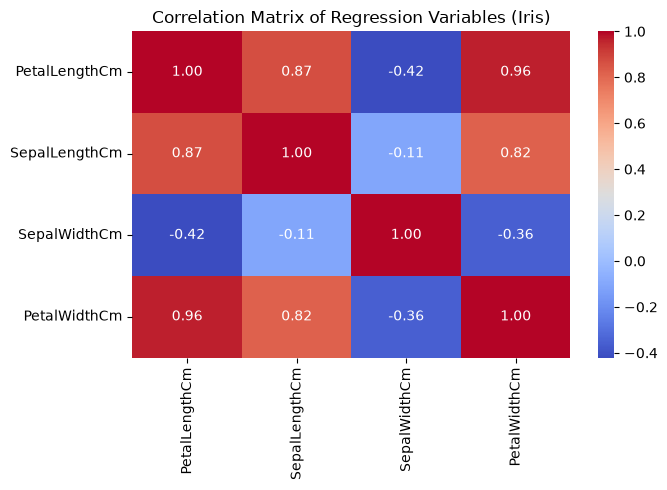

In [3]:
target = "PetalLengthCm"
predictors = ["SepalLengthCm", "SepalWidthCm", "PetalWidthCm"]
reg_df = df[[target] + predictors].dropna().copy()
print(f"Regression dataset: {len(reg_df)} rows")
print(reg_df.describe().T)

plt.figure(figsize=(7, 5))
sns.heatmap(reg_df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Matrix of Regression Variables (Iris)")
plt.tight_layout()
plt.show()

### 5. Prediction & Performance Metrics
Generate predictions on the test set and compute R² (proportion of variance explained), RMSE (root mean squared error, in the target's units), and MAE (mean absolute error). Together these metrics capture both accuracy and error magnitude.

In [4]:
X, y = reg_df[predictors], reg_df[target]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
print("Train set:", len(X_train), "Test set:", len(X_test))

model = sm.OLS(y_train, sm.add_constant(X_train)).fit()
print(model.summary())

coefficients = pd.DataFrame({
    "Coefficient": model.params,
    "Std Error": model.bse,
    "t-statistic": model.tvalues,
    "p-value": model.pvalues
})
print(coefficients.round(4))

Train set: 120 Test set: 30
                            OLS Regression Results                            
Dep. Variable:          PetalLengthCm   R-squared:                       0.970
Model:                            OLS   Adj. R-squared:                  0.969
Method:                 Least Squares   F-statistic:                     1250.
Date:                Thu, 29 Oct 2026   Prob (F-statistic):           4.06e-88
Time:                        04:04:10   Log-Likelihood:                -26.629
No. Observations:                 120   AIC:                             61.26
Df Residuals:                     116   BIC:                             72.41
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const            -

### 6. Variance Inflation Factor (VIF) — Multicollinearity Check
Compute VIF for each predictor. VIF > 5 indicates moderate multicollinearity; VIF > 10 signals severe multicollinearity that can destabilise coefficient estimates and inflate standard errors. Predictors with high VIF may need to be removed or combined.

Train R2: 0.9700 | Adj R2: 0.9692
Test  R2: 0.9604 | RMSE: 0.3604 | MAE: 0.2606


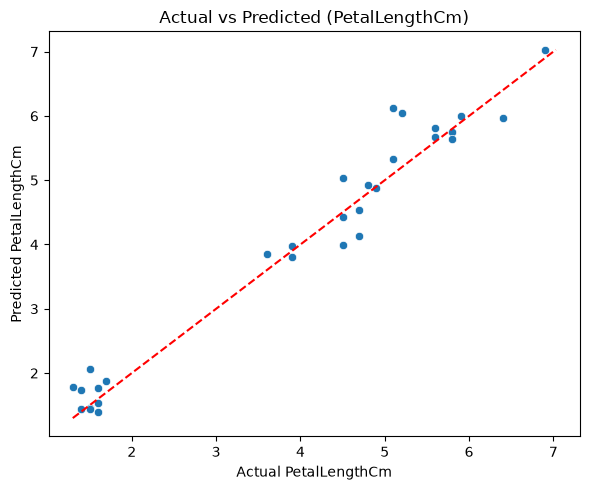

In [5]:
y_pred = model.predict(sm.add_constant(X_test))
mse = mean_squared_error(y_test, y_pred)
rmse, mae = np.sqrt(mse), mean_absolute_error(y_test, y_pred)
test_r2 = r2_score(y_test, y_pred)
print(f"Train R2: {model.rsquared:.4f} | Adj R2: {model.rsquared_adj:.4f}")
print(f"Test  R2: {test_r2:.4f} | RMSE: {rmse:.4f} | MAE: {mae:.4f}")

plt.figure(figsize=(6, 5))
sns.scatterplot(x=y_test, y=y_pred)
lims = [min(float(y_test.min()), float(y_pred.min())), max(float(y_test.max()), float(y_pred.max()))]
plt.plot(lims, lims, "r--")
plt.xlabel("Actual PetalLengthCm")
plt.ylabel("Predicted PetalLengthCm")
plt.title("Actual vs Predicted (PetalLengthCm)")
plt.tight_layout()
plt.show()

### 7. Residual Analysis
Plot residuals (actual − predicted) against fitted values. A random scatter around zero indicates homoscedasticity (constant variance). Systematic patterns suggest model misspecification or heteroscedasticity.

        Variable    VIF
1  SepalLengthCm  3.160
2   SepalWidthCm  1.296
3   PetalWidthCm  3.590


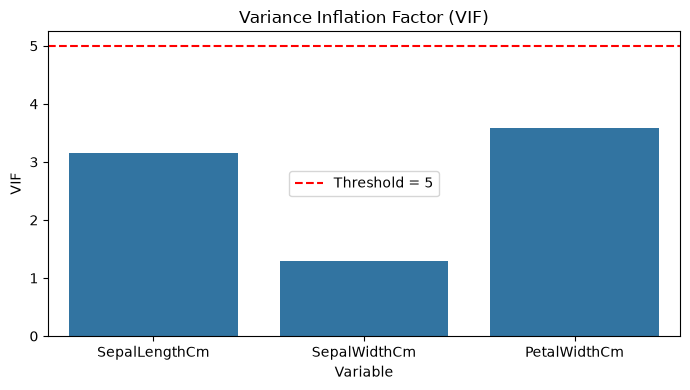

In [6]:
X_vif = sm.add_constant(X_train)
vif = pd.DataFrame({
    "Variable": X_vif.columns,
    "VIF": [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
})
vif = vif[vif["Variable"] != "const"]
print(vif.round(3))

plt.figure(figsize=(7, 4))
sns.barplot(data=vif, x="Variable", y="VIF")
plt.axhline(5, color="red", linestyle="--", label="Threshold = 5")
plt.title("Variance Inflation Factor (VIF)")
plt.legend()
plt.tight_layout()
plt.show()

### 8. Q-Q Plot — Normality of Residuals
A Quantile-Quantile plot compares the empirical distribution of residuals to the theoretical normal distribution. Points falling along the diagonal line confirm the OLS assumption of normally distributed errors, which underpins valid hypothesis tests on coefficients.

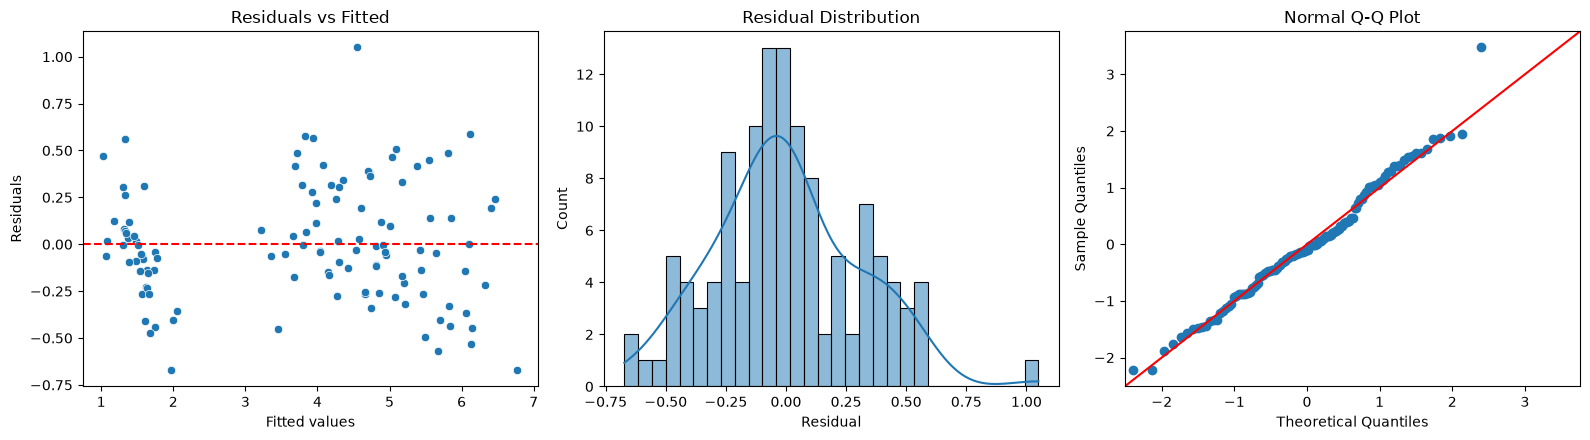

In [7]:
fitted, residuals = model.fittedvalues, model.resid
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

sns.scatterplot(x=fitted, y=residuals, ax=axes[0])
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set(xlabel="Fitted values", ylabel="Residuals", title="Residuals vs Fitted")

sns.histplot(residuals, bins=30, kde=True, ax=axes[1])
axes[1].set(xlabel="Residual", title="Residual Distribution")

sm.qqplot(residuals, line="45", fit=True, ax=axes[2])
axes[2].set(title="Normal Q-Q Plot")
plt.tight_layout()
plt.show()

### 9. Cook's Distance — Influential Point Detection
Cook's Distance measures how much each observation shifts the fitted values if it were removed. Observations with Cook's D > 4/n are flagged as potentially influential and may warrant closer inspection or removal.

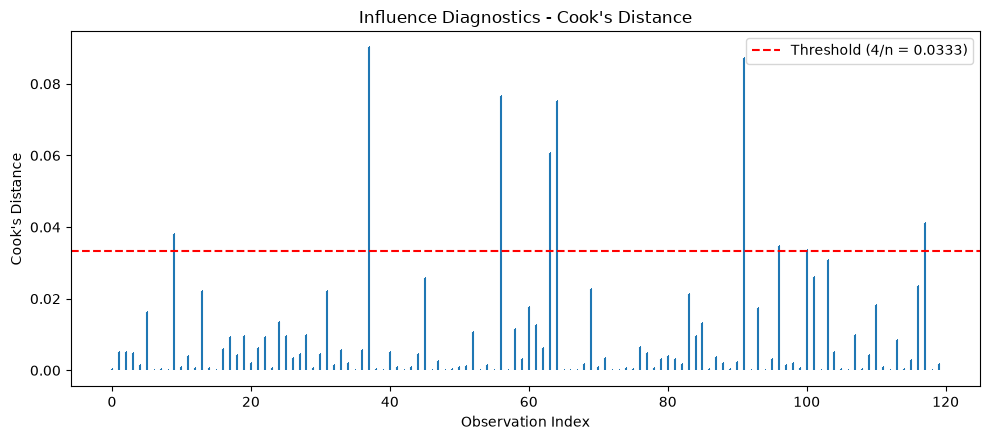

Influential observations count: 9


In [8]:
influence = OLSInfluence(model)
diagnostics = pd.DataFrame({
    "Actual": y_train,
    "Fitted": fitted,
    "Residual": residuals,
    "Std. Residual": influence.resid_studentized_internal,
    "Cook's D": influence.cooks_distance[0]
})
n = len(X_train)
threshold = 4 / n

plt.figure(figsize=(10, 4.5))
plt.stem(np.arange(n), diagnostics["Cook's D"], markerfmt=",", basefmt=" ")
plt.axhline(threshold, color="red", linestyle="--", label=f"Threshold (4/n = {threshold:.4f})")
plt.xlabel("Observation Index")
plt.ylabel("Cook's Distance")
plt.title("Influence Diagnostics - Cook's Distance")
plt.legend()
plt.tight_layout()
plt.show()

influential = diagnostics[diagnostics["Cook's D"] > threshold]
print("Influential observations count:", len(influential))

### 10. Export Regression Results
Save predictions, residuals, and diagnostic metrics to CSV for further analysis or reporting.

In [9]:
summary = pd.DataFrame({
    "Metric": ["Training R2", "Adjusted R2", "Test R2", "Test MSE", "Test RMSE", "Test MAE", "Maximum VIF", "Influential observations"],
    "Value": [model.rsquared, model.rsquared_adj, test_r2, mse, rmse, mae, vif["VIF"].max(), len(influential)]
})
print(summary)

coefficients.to_csv("regression_coefficients.csv")
vif.to_csv("vif_results.csv", index=False)
diagnostics.to_csv("regression_diagnostics.csv")
summary.to_csv("regression_summary.csv", index=False)
print("Saved regression results to CSV files.")

                     Metric     Value
0               Training R2  0.969994
1               Adjusted R2  0.969218
2                   Test R2  0.960359
3                  Test MSE  0.129920
4                 Test RMSE  0.360444
5                  Test MAE  0.260617
6               Maximum VIF  3.590046
7  Influential observations  9.000000
Saved regression results to CSV files.
